# Лабораторная 1. Трёхмерное течение за турбиной: решение Навье–Стокса

**10 октября 2026. Один эксперимент — случай 1L.**
В этом ноутбуке выполняются численное решение PDE, подбор вязкости, сравнение с экспериментом
и проверки сетки и шага времени. Используем три пространственные координаты, три компоненты скорости и время.
Представление уравнения — одно дерево выражения и его матрица смежности.

Запуск всех ячеек из папки лабораторной: Python из `.venv`, зависимости в `requirements.txt`.
`make_preparation.py` создаёт ноутбук; `execute_preparation.py` выполняет его.
Исходные измерения уже находятся в `data/turbine_1L/`.
Для повторной загрузки **только выбранных кадров** предназначен `fetch_experiment.py`;
ноутбук не скачивает полный архив. Расчётные результаты и графики сохраняются в `outputs/turbine_1L/`.

## 1. Статья, физическая задача и измерения

Hillestad J. N., Yadala S., Li L., Hearst R. J., Worth N. A. (2026).
*Volumetric three-dimensional experimental measurement of vortex dynamics in a rotating wake*.
**Physical Review Fluids 11, 014701**. [Статья](https://doi.org/10.1103/9pwb-ky8n).
[Открытый экспериментальный архив, DataverseNO V1](https://doi.org/10.18710/SX0ZQT), CC0.

Авторы исследуют взаимодействие вихрей от лопастей, ступицы и опоры в ближнем следе свободно вращающейся турбины.
Вода в канале NTNU приводит двухлопастный ротор во вращение; за ротором измеряют объёмную скорость.
Это **водная модель ветротурбины**. Перенос результатов на воздух требует динамического подобия.
Наша задача по этим данным — воспроизвести скорость решением Навье–Стокса и исследовать возможность подбора вязкости;
она отличается от цели авторов статьи.

Выбран только **случай 1L**.

| Величина | Значение |
|---|---|
| Количество турбин | Одна |
| Диаметр ротора $D$ | 45 мм |
| Скорость набегающего потока $U_\infty$ | 0.4 м/с |
| Интенсивность турбулентности $I$ | 5% |
| Число Рейнольдса $Re_D$ | $\approx 2\cdot10^4$ |
| Быстроходность $\lambda$ | $\approx 4$ |

$$Re_D=\frac{U_\infty D}{\nu},\qquad I=\frac{\sigma_u}{U_\infty},\qquad
\lambda=\frac{\Omega_r D}{2U_\infty}.$$

$\Omega_r$ — угловая скорость ротора; её можно определить по записи угла поворота.
Параметры 1L взяты из локальной копии `00_README.txt`; быстроходность — из аннотации
[статьи Hillestad et al. (2026)](https://doi.org/10.1103/9pwb-ky8n).
Скорости получены экспериментально методом PTV/Shake-the-Box и преобразованы в эйлеровы поля методом VIC#.
Это обработанные измерения, а не DNS и не независимые сырые треки частиц.

Файл `1WT_rand_100_2D.zip` содержит **объёмные** поля, несмотря на `2D` в названии.
Полный архив имеет размер 65 984 746 642 байта, для распаковки README требует около 225 ГБ.
Загружены 18 кадров **2732, 2737, …, 2817**, файлы масштаба и угла ротора, README.
ZIP прочитан диапазонами байтов; для извлечённых файлов проверены CRC32 и размер,
SHA-256 записаны в `subset_provenance.json`. Полный архив не загружался.

In [1]:
from pathlib import Path
import json
import numpy as np
import networkx as nx
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lab01.graphs import navier_stokes_tree, export_dag, plot_tree, plot_adjacency
from lab01.experiment import prepare_measurements, BOUNDS, observation_points
from lab01.symbolic import symbolic_equations

ROOT=Path.cwd()
OUT=ROOT/'outputs'/'turbine_1L'
OUT.mkdir(parents=True,exist_ok=True)
measurements=prepare_measurements(ROOT/'data'/'turbine_1L')
assert measurements['velocity'].shape[-1]==3 and np.isfinite(measurements['velocity']).all()
print('Кадры:',measurements['frame_ids'])
print('Время относительно первого выбранного кадра, с:',measurements['times'])
print('Форма сохранённого фрагмента [t,x,y,z,компонента]:',measurements['velocity'].shape)
print('Исходная частота: 500 Гц; шаг выбранных кадров:',np.diff(measurements['times'])[0],'с')
print('Единицы координат после чтения: м; скорости: м/с')

Кадры: [2732 2737 2742 2747 2752 2757 2762 2767 2772 2777 2782 2787 2792 2797
 2802 2807 2812 2817]
Время относительно первого выбранного кадра, с: [0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15 0.16 0.17]
Форма сохранённого фрагмента [t,x,y,z,компонента]: (18, 53, 33, 33, 3)
Исходная частота: 500 Гц; шаг выбранных кадров: 0.01 с
Единицы координат после чтения: м; скорости: м/с


## 2. Уравнение и смысл слагаемых

Для несжимаемой ньютоновской жидкости при постоянных $\rho,\nu$:

$$\partial_t\mathbf u+(\mathbf u\cdot\nabla)\mathbf u
=-\frac{1}{\rho}\nabla p+\nu\Delta\mathbf u,\qquad\nabla\cdot\mathbf u=0.$$

Здесь $\mathbf u=\mathbf u(x,y,z,t)=(u,v,w)$ и $p=p(x,y,z,t)$;
$\mathbf x\in\Omega\subset\mathbb R^3$. Потенциал тяжести включён в модифицированное давление.

| Часть | Физический смысл |
|---|---|
| $\partial_t\mathbf u$ | Изменение скорости со временем в неподвижной точке |
| $(\mathbf u\cdot\nabla)\mathbf u$ | Перенос импульса потоком через неоднородное поле скорости |
| $-\nabla p/\rho$ | Ускорение вследствие неоднородного давления |
| $\nu\Delta\mathbf u$ | Вязкая диффузия импульса |
| $\nabla\cdot\mathbf u=0$ | Несжимаемость, локальный баланс объёма |

Решается **исходная система скорости–давления**, без перехода к форме Лэмба или уравнению завихренности.
Постановка — несжимаемый вариант Навье–Стокса в подобласти экспериментального следа.
Аннотация статьи и README проверены; точное пронумерованное уравнение из закрытого полного текста статьи здесь не цитируется.

## 3. Прямая начально-краевая задача

$$\Omega=[0.020,0.100]\times[-0.024,0.024]\times[-0.024,0.024]\ \text{м}^3.$$

Выбран объём ниже по потоку, $x/D=0.44\ldots2.22$, с искусственными границами внутри измеряемого объёма.
Геометрия турбины в сетку не включается; расчёт предполагает свободную жидкость в этой подобласти.
Для каждого пробного $\nu$:

$$\mathbf u_\nu(t_0)=P_h\mathcal I_h\mathbf u_{exp}(t_0),\qquad
\mathbf u_\nu|_{\partial\Omega}=\mathbf g_h(t).$$

$\mathcal I_h$ — пространственная линейная интерполяция, $P_h$ — коррекция начальной скорости.
Для MAC это согласованная дискретная проекция на бездивергентное поле;
для FEniCSx используется приближённая коррекция IPCS с отдельно измеряемой дивергенцией.
Граничная скорость берётся из измерений во всём окне и линейно интерполируется во времени.
Чтобы задача давления была совместна, из каждой нормальной компоненты $g_n$ вычитается одна и та же поправка
$\delta=Q/|\partial\Omega|$, где $Q=\int_{\partial\Omega}\mathbf g\cdot\mathbf n\,dS$.
Проверяется дискретный аналог нулевого потока. Тангенциальные значения задаются через фиктивные ячейки.
Это условия на искусственной границе в жидкости, поэтому $\mathbf g$ не заменяется нулём.

Начальные и граничные данные одинаковы при всех пробных вязкостях.
Давление отсутствует в измерениях; проекция вычисляет множитель $p/\rho$ с нулевым средним.
Сохранённый `pressure_multiplier_final` относится к последней стадии проекции;
он не используется как независимо проверенное физическое поле давления.

## 4. Обратная задача и сравнение с данными

$$\nu=\nu_{ref}e^\eta,\quad \nu_{ref}=U_\infty D/Re_D=9\cdot10^{-7}\ \text{м}^2/\text{с},$$
$$\eta^*=\arg\min_\eta J(\nu_{ref}e^\eta),\qquad
J(\nu)=\sum_{n,j}\left\|\frac{H_j\mathbf u_\nu(t_n)-\mathbf u_{exp}(\mathbf x_j,t_n)}{0.4}\right\|^2.$$

**SciPy `least_squares`, TRF**, положительная вязкость через экспоненту.
При каждой оценке ошибки заново интегрируется PDE; это не регрессия временного ряда.
$H_j$ — перенос расчётной скорости в одну из **539 фиксированных внутренних точек**
(трёхлинейная интерполяция для MAC, вычисление конечного элемента для FEniCSx):
$x\in[35,85]$ мм (11 точек), $y,z\in[-15,15]$ мм (по 7 точек).
Для всех сеток сравниваются одни и те же физические точки.

Диапазон $[0.5,2]\nu_{ref}$ — исследовательский диапазон вокруг оценки по приблизительному $Re$;
он **не** обоснован измеренной температурой воды. Опорное значение также не является точным измерением вязкости.

| Окно | Кадры | Относительное время | Использование |
|---|---|---|---|
| Подбор | 2732–2777 с шагом 5 | 0–0.09 с | Подбор $\nu$; первый кадр — начальное условие |
| Контроль | 2782–2817 с шагом 5 | 0.10–0.17 с | $\nu$ фиксировано; отдельное начальное поле из кадра 2782 |

Начальные кадры каждого окна и граничные точки исключены из ошибки.
Контроль оценивает **условное воспроизведение течения при известных измеренных границах**, а не самостоятельный прогноз.
Данные исходно записаны при 500 Гц, здесь взят каждый пятый кадр: 100 Гц, без дополнительной фильтрации.
Короткий фрагмент позволяет провести локальный вычислительный эксперимент; он не характеризует всю запись 10.9 с.

## 5. Одно дерево уравнения и матрица смежности

$$F=-(\nabla\mathbf u)\mathbf u-\nabla p/\rho+\nu\Delta\mathbf u.$$

**NetworkX + SymPy**, 16 вершин, 15 рёбер. Повторные вхождения $\mathbf u$ — отдельные листья одного поля.
Корень — итоговая сумма; стрелки идут от входа к операции. Это дерево, частный случай DAG.
$(\nabla\mathbf u)_{ij}=\partial_j u_i$, поэтому произведение матрицы на вектор равно конвективному члену.
Условие несжимаемости и шаг интегрирования учитывает солвер, они не входят в это дерево правой части.

Соглашение задания: $Z_{ij}=1$, если $j$ — вход операции $i$.
При направлении рёбер «вход → операция» это транспонированная стандартная матрица NetworkX.
Одной бинарной матрицы недостаточно для восстановления смысла формулы:
словарь сохраняет операцию, тип результата и **упорядоченные** аргументы (`args`), в частности деления и матричного произведения.

Словарь вершин:
n01 u op= None shape= vector3 args= []
n02 grad op= gradient shape= matrix3x3 args= ['n01']
n03 u op= None shape= vector3 args= []
n04 mv op= matvec shape= vector3 args= ['n02', 'n03']
n05 − op= negate shape= vector3 args= ['n04']
n06 p op= None shape= scalar args= []
n07 grad op= gradient shape= vector3 args= ['n06']
n08 ρ op= None shape= scalar args= []
n09 ÷s op= divide_scalar shape= vector3 args= ['n07', 'n08']
n10 − op= negate shape= vector3 args= ['n09']
n11 + op= add shape= vector3 args= ['n05', 'n10']
n12 ν op= None shape= scalar args= []
n13 u op= None shape= vector3 args= []
n14 Δ op= laplacian shape= vector3 args= ['n13']
n15 ×s op= scale shape= vector3 args= ['n12', 'n14']
n16 + op= add shape= vector3 args= ['n11', 'n15']
Z =
 [[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0 0 0 0 0

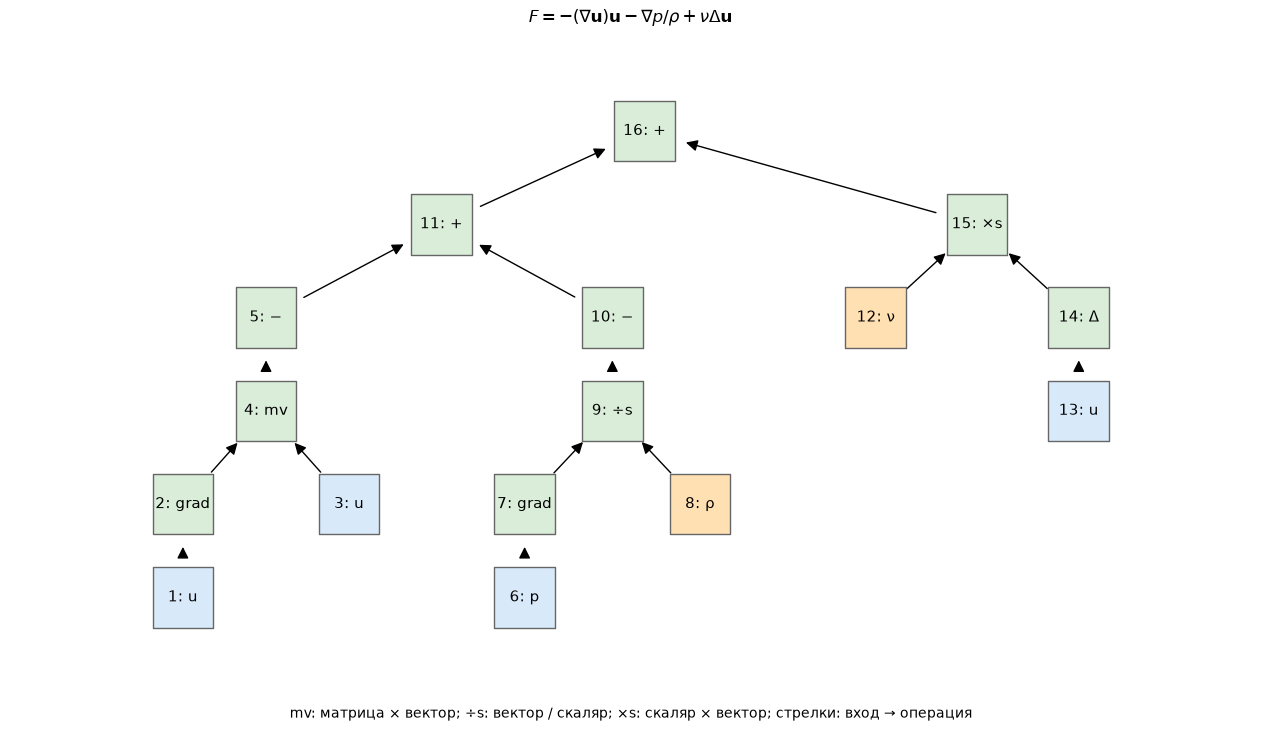

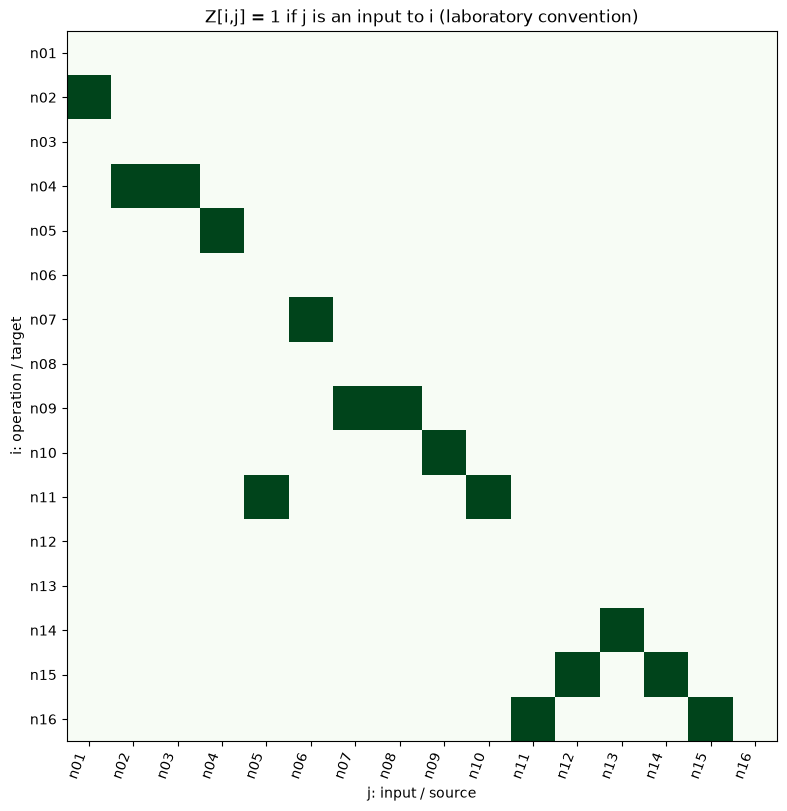

In [2]:
tree=navier_stokes_tree()
graph=nx.DiGraph(tree.graph)
assert nx.is_tree(graph) and len(graph)==16 and graph.number_of_edges()==15
order,Z,_=tree.matrices()
assert order==[f'n{i:02}' for i in range(1,17)]
export_dag(tree,OUT,'navier_stokes_tree')
print('Словарь вершин:')
for node,item in tree.to_dict()['nodes'].items():
    print(node,item['label'],'op=',item['op'],'shape=',item['shape'],'args=',item['args'])
print('Z =\n',Z)
fig=plot_tree(tree);fig.savefig(OUT/'navier_stokes_tree.png',dpi=170,bbox_inches='tight');plt.show()
fig=plot_adjacency(tree);fig.savefig(OUT/'navier_stokes_tree_matrix.png',dpi=170,bbox_inches='tight');plt.show()

In [3]:
# Независимая проверка вычисления дерева на трёхмерных полях.
x,y,z,t=sp.symbols('x y z t');coords=(x,y,z)
u=sp.Matrix([y*z+t,z*x,x*x]);p=x*y+z*z+t*x
nu_value=sp.Rational(1,10);rho_value=sp.Rational(3,2)
lap=lambda a:a.applyfunc(lambda f:sum(sp.diff(f,c,2) for c in coords))
operators={'gradient':lambda a:a.jacobian(coords) if isinstance(a,sp.MatrixBase) else sp.Matrix([sp.diff(a,c) for c in coords]),
           'matvec':lambda a,b:a*b,'negate':lambda a:-a,'divide_scalar':lambda a,b:a/b,
           'add':lambda a,b:a+b,'laplacian':lap,'scale':lambda a,b:a*b}
values={'n01':u,'n03':u,'n13':u,'n06':p,'n08':rho_value,'n12':nu_value}
actual=tree.evaluate(values,operators)['n16']
expected=-u.jacobian(coords)*u-sp.Matrix([sp.diff(p,c)/rho_value for c in coords])+nu_value*lap(u)
assert (actual-expected).applyfunc(sp.simplify)==sp.zeros(3,1)
print('Дерево точно воспроизводит исходную правую часть, включая давление и вязкость.')
display(actual)

Дерево точно воспроизводит исходную правую часть, включая давление и вязкость.


Matrix([
[-2*t/3 - x**2*y - x*z**2 - 2*y/3],
[     -x**3 - 2*x/3 - z*(t + y*z)],
[    -2*x*(t + y*z) - 4*z/3 + 1/5]])

## 6. Реализованный солвер

В `lab01/solver.py` реализована **трёхмерная разнесённая сетка MAC**:
скорости на гранях ячеек, давление в центрах. Основная сетка — $36\times24\times24$ ячеек,
шаги $(2.222,2.000,2.000)$ мм. Это грубая аппроксимация, разрешение DNS не заявляется.

Перенос — противопоточная разность первого порядка; вязкая диффузия — центральная разность второго порядка.
По времени — SSP-RK3 с проекцией на каждой стадии. Проекция использует

$$\Delta_h q=\frac{\nabla_h\cdot\mathbf u^*}{\alpha\Delta t},\qquad
\mathbf u^{new}=\mathbf u^*-\alpha\Delta t\nabla_hq,$$

с однородным нормальным градиентом поправки давления, совместным нулевым потоком и нулевым средним $q$.
Задача Пуассона решается DCT-II средствами SciPy; дискретные градиент и дивергенция согласованы.
Шаг ограничен переносом (CFL 0.35), диффузией и ближайшим моментом наблюдения.
Для проверки используются также сетки $24\times16\times16$, $48\times32\times32$ и CFL 0.175 на основной сетке.

Первоначальная центральная схема переноса дала неустойчивое решение при сгущении сетки и отклонена.
Устойчивая противопоточная схема имеет существенную численную диффузию при высоком $Re$:
её вклад нужно отличать от физической вязкости.
Первый расчёт выполнен этим MAC-солвером на NumPy/SciPy.
Дополнительно FEniCSx 0.11 установлен в изолированное Conda-окружение `.fenicsx`;
сравнение методов приведено ниже, после результатов MAC.
Метод MAC: [Harlow & Welch, 1965](https://doi.org/10.1063/1.1761178);
SSP-RK: [Gottlieb & Shu, 1998](https://doi.org/10.1090/S0025-5718-98-00913-2).

Перед экспериментом проверяем интегратор на точном трёхмерном решении:
$\mathbf u=e^{-\nu t}(\sin z+\cos y,\sin x+\cos z,\sin y+\cos x)$,
$p/\rho=-|\mathbf u|^2/2$, $\nu=0.1$. Эта проверка не используется как экспериментальные данные.

In [4]:
from lab01.verification import abc_error
coarse,div_c=abc_error(12,.005)
fine,div_f=abc_error(24,.0025)
assert fine < .8*coarse and max(div_c,div_f)<1e-12
print(f'Точное 3D-решение, сетка 12³: относительная ошибка {coarse:.6%}')
print(f'Точное 3D-решение, сетка 24³: относительная ошибка {fine:.6%}')
print('Ошибка уменьшается при совместном сгущении сетки и шага времени; порядок сходимости здесь не оцениваем.')

Точное 3D-решение, сетка 12³: относительная ошибка 0.725076%
Точное 3D-решение, сетка 24³: относительная ошибка 0.389113%
Ошибка уменьшается при совместном сгущении сетки и шага времени; порядок сходимости здесь не оцениваем.


## 7. Выполнение вычислительного эксперимента

Следующая ячейка **выполняет**, а не имитирует расчёт: интегрирует систему Навье–Стокса,
подбирает вязкость, считает контрольное окно, профиль ошибки и три проверки дискретизации.
Поле внутри области после начального момента не подставляется из измерений:
оно получается интегрированием PDE. Измерения во времени используются только на границе и при вычислении ошибки.
В рамках одного запуска повторные оценки для одинакового $\nu$ кешируются.

In [5]:
from run_experiment import main
report=main()
# JSON — компактный воспроизводимый отчёт с параметрами и метриками всех запусков.
assert all(r['optimizer_success'] for r in report['runs'])
assert all(np.isfinite(r['validation_calibrated']['relative_l2']) for r in report['runs'])
assert all(r['max_divergence_rms_s_inv']<1e-10 for r in report['runs'])

primary nu=9e-07, J=107.564


primary nu=9.0000001e-07, J=107.564


primary nu=1.7758409e-06, J=107.471


primary nu=1.7758409e-06, J=107.471


primary nu=1.7999811e-06, J=107.468


...

half_time_step nu=1.7999812e-06, J=107.468


half_time_step nu=1.8e-06, J=107.468


half_time_step nu=1.8e-06, J=107.468


half_time_step: nu=1.8e-06, fit=25.497%, validation=24.461%


Saved real experimental calculation to outputs/turbine_1L


## 8. Аппроксимация и ошибки

Аппроксимация — рассчитанное поле $\mathbf u_{\nu^*}(x,y,z,t)$, перенесённое в точки измерения оператором $H$.

$$E_{rel}=\frac{\|H\mathbf u_{\nu^*}-\mathbf u_{exp}\|_2}{\|\mathbf u_{exp}\|_2},\qquad
RMSE=\sqrt{\frac1{3N}\sum_{n,j,c}(u^{calc}_{njc}-u^{exp}_{njc})^2}.$$

Нормы и RMSE объединяют все три компоненты в 539 точках: 9 сравниваемых моментов при подборе,
7 на контроле. Ниже ошибки даны отдельно для опорной и подобранной вязкости.
Простой ориентир «сохранять начальную скорость в точках» рассчитан отдельно и не является решением PDE.

In [6]:
rows=['| Сетка / CFL | ν*, м²/с | E подбора | E контроля | RMSE контроля, м/с |',
      '|---|---:|---:|---:|---:|']
for r in report['runs']:
    rows.append(f"| {'×'.join(map(str,r['grid_cells']))} / {r['cfl']} | {r['nu_fit']:.3g} | {r['fit_calibrated']['relative_l2']:.3%} | {r['validation_calibrated']['relative_l2']:.3%} | {r['validation_calibrated']['rmse_m_per_s']:.5f} |")
display(Markdown('\n'.join(rows)))
r=report['runs'][0]
print('Основная сетка, опорная вязкость:')
print('Подбор:',r['fit_reference'],'\nКонтроль:',r['validation_reference'])
print('Покомпонентный RMSE контроля u,v,w, м/с:',r['validation_calibrated']['component_rmse_m_per_s'])
print('Ориентир с постоянной начальной скоростью:',report['persistence_baseline'])
print('Максимум RMS дискретной дивергенции, 1/с:',r['max_divergence_rms_s_inv'])
print('Максимальная коррекция нормальной граничной скорости, м/с:',r['max_boundary_normal_shift_m_per_s'])

| Сетка / CFL | ν*, м²/с | E подбора | E контроля | RMSE контроля, м/с |
|---|---:|---:|---:|---:|
| 36×24×24 / 0.35 | 1.8e-06 | 25.497% | 24.461% | 0.03318 |
| 24×16×16 / 0.35 | 1.8e-06 | 25.826% | 24.750% | 0.03358 |
| 48×32×32 / 0.35 | 1.8e-06 | 25.354% | 24.357% | 0.03304 |
| 36×24×24 / 0.175 | 1.8e-06 | 25.497% | 24.461% | 0.03318 |

Основная сетка, опорная вязкость:
Подбор: {'rmse_m_per_s': 0.03438886900048965, 'component_rmse_m_per_s': [0.03543612805834432, 0.035777038974864415, 0.03181300431933724], 'relative_l2': 0.2550824711010139, 'observation_vectors': 4851} 
Контроль: {'rmse_m_per_s': 0.03320112712213795, 'component_rmse_m_per_s': [0.03316559554643098, 0.03432193602556386, 0.03207791305631885], 'relative_l2': 0.24473542797770945, 'observation_vectors': 3773}
Покомпонентный RMSE контроля u,v,w, м/с: [0.03313437456623003, 0.034312294940533346, 0.032067970189193884]
Ориентир с постоянной начальной скоростью: {'fit': {'rmse_m_per_s': 0.05254993172323617, 'component_rmse_m_per_s': [0.04957132576047862, 0.05620188894615498, 0.051657693653345674], 'relative_l2': 0.38979375681014056, 'observation_vectors': 4851}, 'validation': {'rmse_m_per_s': 0.053876706151978405, 'component_rmse_m_per_s': [0.053820219254925424, 0.05738256028955997, 0.05018689242547948], 'relative_l2': 0.3971412985356702, 'observation_vectors': 37

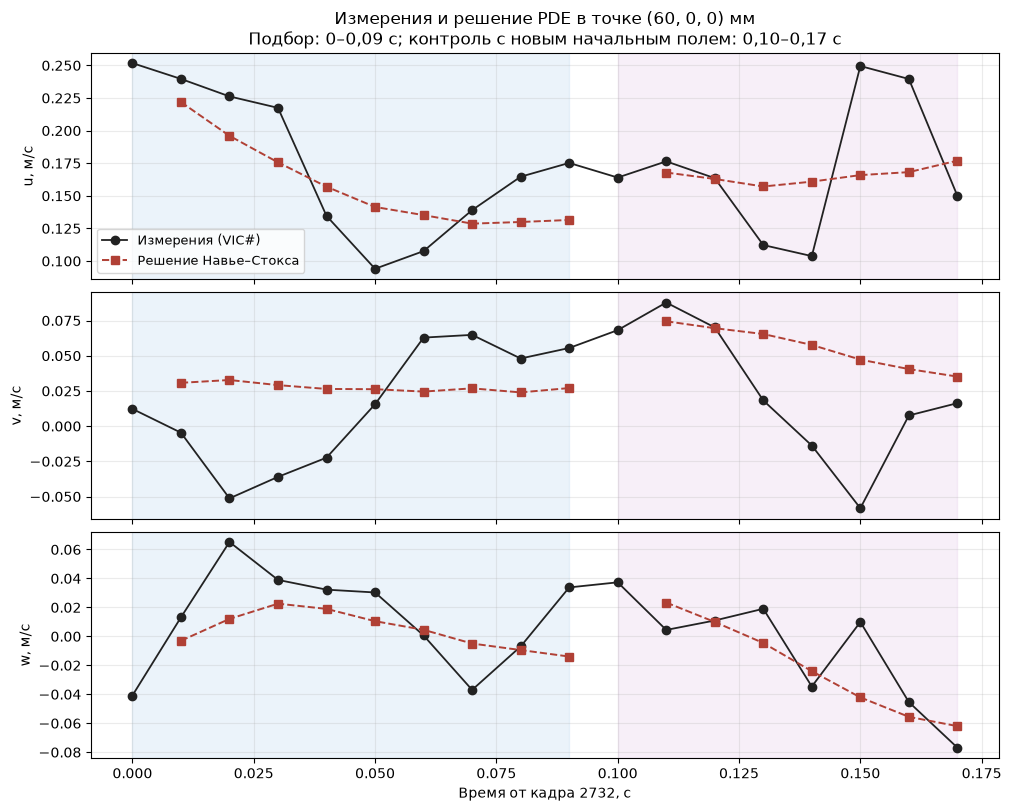

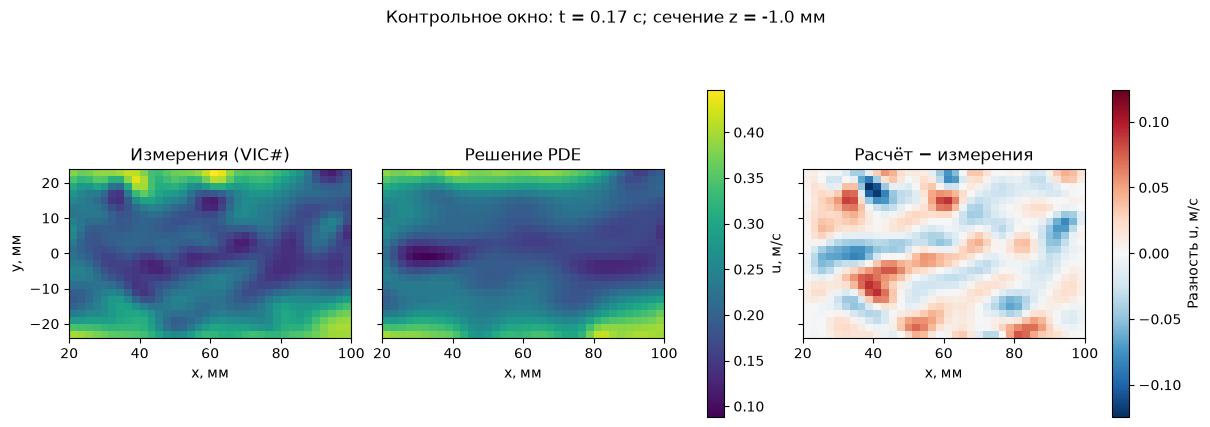

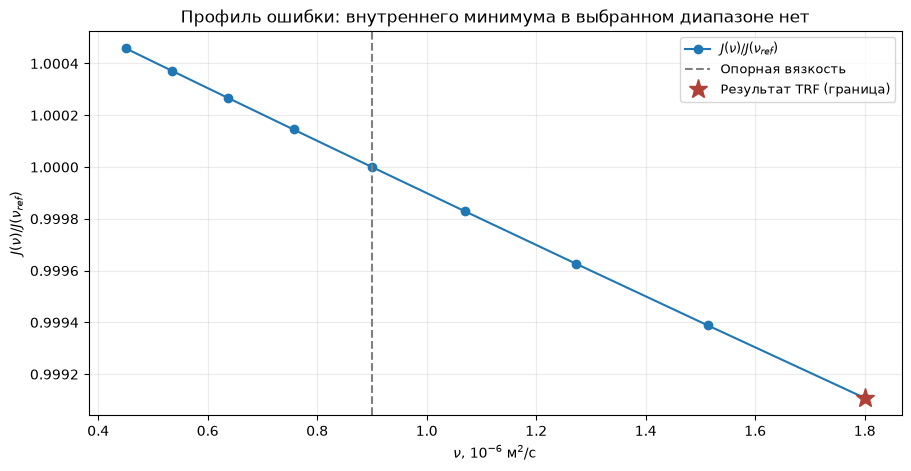

In [7]:
from lab01.plotting import plot_experiment
figures=plot_experiment(OUT,report)
for fig in figures.values():
    display(fig)
    plt.close(fig)

## 9. Что показали подбор и проверки

Важно отделять уменьшение ошибки при изменении сетки от сходимости к эксперименту.
Ниже сравниваются **численные поля друг с другом** в одинаковых физических точках;
поле наиболее мелкой сетки — ориентир, а не точное решение.

In [8]:
print(json.dumps(report['discretization_changes_relative_l2'],indent=2,ensure_ascii=False))
j=np.array([a['J'] for a in r['profile']])
variation=(j.max()-j.min())/j.mean()
print(f'Размах J на всём диапазоне вязкости: {variation:.3%} от среднего J')
print('Оптимум на границе диапазона:',r['fit_at_bound'])
print('Статус TRF:',r['optimizer_message'])
display(Markdown(f'''Получено **ν* = {r['nu_fit']:.3g} м²/с**, на верхней границе выбранного диапазона.
Относительная ошибка на контроле основной сетки — **{r['validation_calibrated']['relative_l2']:.2%}**,
RMSE — **{r['validation_calibrated']['rmse_m_per_s']:.5f} м/с**.
Изменение J на всём диапазоне — всего **{variation:.3%}**.
Внутренний минимум не обнаружен, надёжная идентификация молекулярной вязкости не получена.'''))

{
  "coarser": {
    "fit": 0.05974043487913929,
    "validation": 0.0608980817572484
  },
  "primary": {
    "fit": 0.022588033446303404,
    "validation": 0.022251821654250808
  },
  "time_step_change": {
    "fit": 1.759295361190023e-06,
    "validation": 1.7529641797878132e-06
  }
}
Размах J на всём диапазоне вязкости: 0.135% от среднего J
Оптимум на границе диапазона: True
Статус TRF: `gtol` termination condition is satisfied.


Получено **ν* = 1.8e-06 м²/с**, на верхней границе выбранного диапазона.
Относительная ошибка на контроле основной сетки — **24.46%**,
RMSE — **0.03318 м/с**.
Изменение J на всём диапазоне — всего **0.135%**.
Внутренний минимум не обнаружен, надёжная идентификация молекулярной вязкости не получена.

Численная диффузия противопоточного переноса имеет характерный масштаб $|u_i|h_i/2$;
при $u\sim0.4$ м/с и $h\sim2$ мм он порядка $4\cdot10^{-4}$ м²/с,
значительно больше исследуемой молекулярной вязкости. Это одна из причин слабой чувствительности.
Погрешности пространственной и временной интерполяции границ, обработки VIC# и неполное разрешение малых масштабов
также входят в наблюдаемую ошибку. Сгущение сетки и уменьшение шага — проверки чувствительности,
а не доказательство разрешения всей турбулентности.

**Получено в этой работе:** одно дерево и его матрица/словарь, решение трёхмерной начально-краевой задачи,
подбор параметра, проверка на отдельном временном окне, RMSE и относительные ошибки,
графики данных/решения/ошибки, профиль параметра и проверки дискретизации.
Ограничения: короткий фрагмент одного случая, известные измеренные границы,
обработанные данные вместо независимых сырых PTV, грубая схема и вязкость на границе диапазона.
Эти результаты не следует представлять как точное восстановление вязкости или автономный прогноз следа.

## 10. Проверка FEniCSx и сравнение солверов

FEniCSx 0.11.0 установлен из conda-forge, Python 3.12 и MPICH.
Окружение воспроизводится по `environments/fenicsx.yml`; команды запуска описаны в `docs/fenicsx.md`.
Для повторения расчёта из терминала:

```sh
.fenicsx/bin/python run_fenics_experiment.py --phase verify
.fenicsx/bin/python run_fenics_experiment.py --phase primary
```

**Реализация:** трёхмерные тетраэдры, скорость P2 и давление P1, инкрементальная
коррекция давления IPCS. Перенос и диффузия аппроксимируются полунеявно по
Crank–Nicolson; переносящая скорость экстраполируется по AB2. Искусственная
вязкость и противопоточная схема не добавляются.
[Формулировка DOLFINx](https://jsdokken.com/dolfinx-tutorial/chapter2/ns_code2.html)
адаптирована к заданной скорости на всей границе и постоянному ядру давления.

Сначала решается точная задача: переносимое вихревое поле Бельтрами при
$\nu=9\cdot10^{-7}$ м²/с, $\mathbf U=(0.25,0,0)$ м/с и амплитуде $A=0.04$ м/с.
При $k=2\pi/\ell$:

$$\mathbf u=\mathbf U+A e^{-\nu k^2t}
\begin{pmatrix}\sin(kz)+\cos(ky)\\
\sin(k(x-Ut))+\cos(kz)\\
\sin(ky)+\cos(k(x-Ut))\end{pmatrix},\qquad
p/\rho=-|\mathbf u-\mathbf U|^2/2.$$

Это точное решение исходной PDE; оно не добавляется к экспериментальным данным.
Ошибка вихревой части имеет знаменатель $\|\mathbf u_{exact}-\mathbf U\|_2$;
её нельзя смешивать с ошибкой полной скорости.
В проверке задано точное начальное давление; в эксперименте начальное давление
равно нулю, поскольку оно не измерено.

Сравнение с экспериментом использует прежние 18 кадров, 539 точек, временные окна,
правила интерполяции и коррекции общего граничного потока. Начальные проекции
различаются по дискретизации. IPCS с P1-давлением не обеспечивает поточечно нулевую
дивергенцию; её RMS приводится отдельно. Следующая ячейка читает **отчёты реально
выполненных запусков**; повторный расчёт можно включить явно.

| Проверка | Сетка | Δt, с | ℓ, мм | Ошибка вихревой части |
|---|---|---:|---:|---:|
| MAC upwind | 36×24×24 | CFL | 32 | 32.44% |
| FEniCSx P2/P1 IPCS | 12×8×8 | 0.001 | 32 | 14.26% |
| FEniCSx P2/P1 IPCS | 18×12×12 | 0.001 | 32 | 6.09% |
| FEniCSx P2/P1 IPCS | 18×12×12 | 0.0005 | 32 | 6.09% |
| MAC upwind | 36×24×24 | CFL | 16 | 61.16% |
| FEniCSx P2/P1 IPCS | 12×8×8 | 0.001 | 16 | 73.36% |
| FEniCSx P2/P1 IPCS | 18×12×12 | 0.001 | 16 | 43.68% |
| FEniCSx P2/P1 IPCS | 18×12×12 | 0.0005 | 16 | 43.71% |

| Метод | ν, м²/с | Ошибка подбора | Ошибка контроля | RMSE контроля, м/с |
|---|---:|---:|---:|---:|
| MAC, опорная ν | 9e-07 | 25.51% | 24.47% | 0.03320 |
| MAC, подобранная ν | 1.8e-06 | 25.50% | 24.46% | 0.03318 |
| FEniCSx P2/P1, опорная ν | 9e-07 | 30.76% | 28.70% | 0.03894 |
| FEniCSx P2/P1, подобранная ν | 1.8e-06 | 29.94% | 28.16% | 0.03820 |

FEniCSx: степени свободы скорости и давления: 69375 3211
RMS дивергенции FEniCSx, максимум по сохранённым кадрам, 1/с: 55.96258246239084
Максимальный суммарный поток через границу, м³/с: 5.151879378327269e-18
Статус подбора: `gtol` termination condition is satisfied. ; оптимум на границе: True


| Проверка FEniCSx при опорной ν | Сетка | Δt, с | Ошибка контроля |
|---|---|---:|---:|
| coarser | 12×8×8 | 0.001 | 30.10% |
| primary | 18×12×12 | 0.001 | 28.70% |
| finer | 27×18×18 | 0.001 | 27.85% |
| half_dt | 18×12×12 | 0.0005 | 28.70% |

{
  "nu_for_checks": 9e-07,
  "control_error_at_reference_nu": {
    "coarser": 0.30101259179732454,
    "primary": 0.287047861203454,
    "finer": 0.2785461635195878,
    "half_dt": 0.2869813879987337
  },
  "halved_dt_field_difference_relative_l2": 0.004853240902697388,
  "primary_vs_finer_field_difference_relative_l2": 0.14415866342717884,
  "maximum_strong_divergence_of_reported_run_s_inv": {
    "coarser": 48.01132125536216,
    "primary": 55.96258246239084,
    "finer": 71.47897849876857,
    "half_dt": 65.60685559402121
  },
  "interpretation": "Same physical observation points; differing initial projections. These checks do not establish convergence or pointwise incompressibility."
}


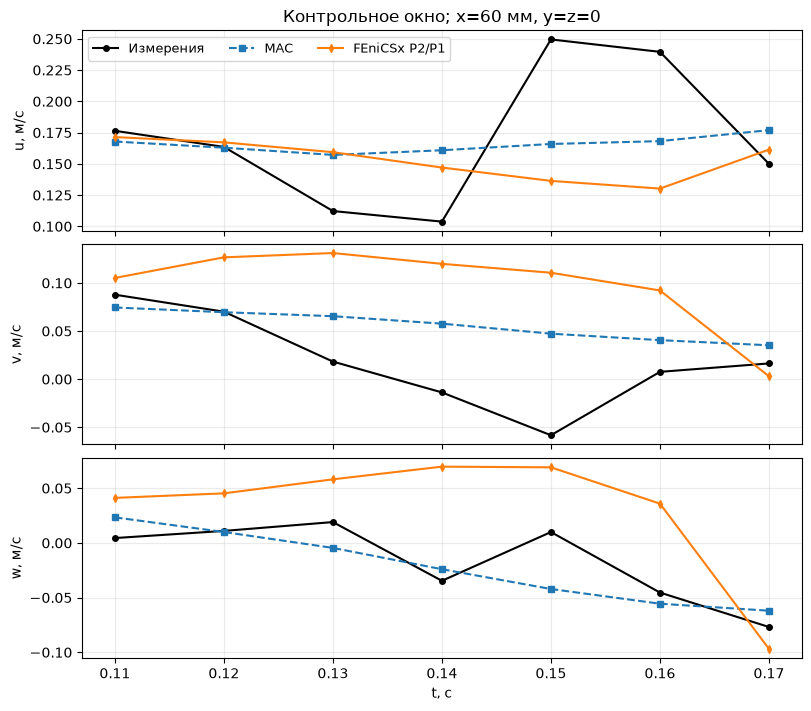

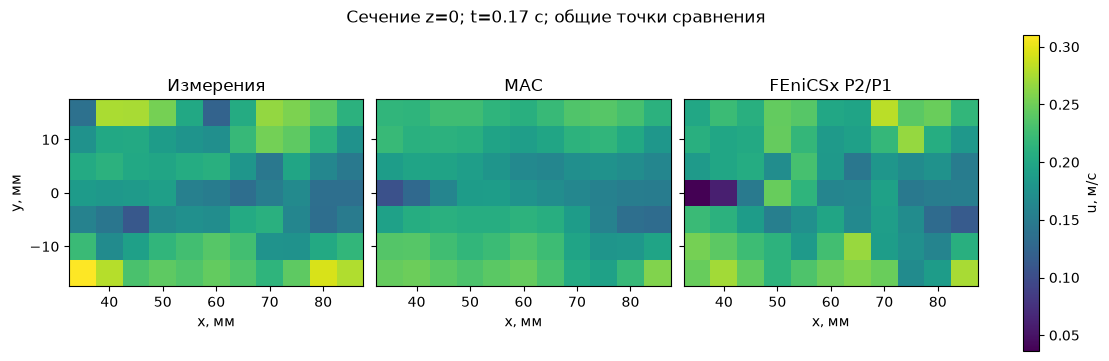

In [2]:
import subprocess
from lab01.fenics_comparison import load_comparison, comparison_figures, discretization_report
RECOMPUTE_FENICSX=False
if RECOMPUTE_FENICSX:
    for phase in ('verify','primary','coarser','finer','half_dt'):
        subprocess.run([str(ROOT/'.fenicsx/bin/python'),str(ROOT/'run_fenics_experiment.py'),
                        '--phase',phase],cwd=ROOT,check=True)
mac,fem,verification=load_comparison(OUT)
assert fem['dolfinx_version']=='0.11.0'
assert np.isfinite(fem['validation_calibrated']['relative_l2'])
rows=['| Проверка | Сетка | Δt, с | ℓ, мм | Ошибка вихревой части |',
      '|---|---|---:|---:|---:|']
for a in verification['results']:
    rows.append(f"| {a['solver']} | {'×'.join(map(str,a['grid']))} | {a.get('dt_s','CFL')} | {1000*a['wavelength_m']:g} | {a['relative_fluctuation_error']:.2%} |")
display(Markdown('\n'.join(rows)))
rows=['| Метод | ν, м²/с | Ошибка подбора | Ошибка контроля | RMSE контроля, м/с |',
      '|---|---:|---:|---:|---:|']
for name,a in [('MAC',mac),('FEniCSx P2/P1',fem)]:
    for mode,label in [('reference','опорная ν'),('calibrated','подобранная ν')]:
        rows.append(f"| {name}, {label} | {a['nu_reference'] if mode=='reference' else a['nu_fit']:.4g} | {a['fit_'+mode]['relative_l2']:.2%} | {a['validation_'+mode]['relative_l2']:.2%} | {a['validation_'+mode]['rmse_m_per_s']:.5f} |")
display(Markdown('\n'.join(rows)))
print('FEniCSx: степени свободы скорости и давления:',fem['velocity_dofs'],fem['pressure_dofs'])
print('RMS дивергенции FEniCSx, максимум по сохранённым кадрам, 1/с:',fem['max_divergence_rms_s_inv'])
print('Максимальный суммарный поток через границу, м³/с:',fem['max_boundary_flux_m3_per_s'])
print('Статус подбора:',fem['optimizer_message'],'; оптимум на границе:',fem['fit_at_bound'])
runs_fem,checks_fem=discretization_report(OUT)
display(Markdown('\n'.join(['| Проверка FEniCSx при опорной ν | Сетка | Δt, с | Ошибка контроля |',
    '|---|---|---:|---:|']+[f"| {name} | {'×'.join(map(str,a['grid_subdivisions']))} | {a['dt_s']} | {a['validation_reference']['relative_l2']:.2%} |" for name,a in runs_fem.items()])))
print(json.dumps(checks_fem,ensure_ascii=False,indent=2))
for fig in comparison_figures(OUT).values():
    display(fig);plt.close(fig)

Снижение ошибки на точной задаче показывает улучшение конкретной численной
аппроксимации. Оно не гарантирует меньшую ошибку относительно обработанных
экспериментальных измерений. Начальное давление, разрешение сетки, условия
на искусственных границах, обработка VIC# и недостаточная длительность записи
влияют на сравнение. Данные здесь не заменяются новым экспериментом.
Надёжность определения молекулярной вязкости требует отдельного анализа чувствительности.
Заметная сильная дивергенция и чувствительность к сетке ограничивают достоверность
данной реализации IPCS на высоком числе Рейнольдса. Меньший шаг времени сам по себе
не устраняет эти пространственные ошибки. Результат не следует считать подтверждённым
точным решением течения или доказательством качества библиотеки в целом.

## 11. Источники и воспроизводимость

1. [Hillestad et al., Physical Review Fluids 11, 014701 (2026)](https://doi.org/10.1103/9pwb-ky8n) — исследуемое явление, аннотация.
2. [DataverseNO, DOI 10.18710/SX0ZQT](https://doi.org/10.18710/SX0ZQT) — случай 1L, открытые измерения и README.
   [Прямая ссылка на ZIP 1L](https://dataverse.no/api/access/datafile/:persistentId?persistentId=doi:10.18710/SX0ZQT/FWZUIM).
3. [Harlow & Welch (1965), Physics of Fluids 8, 2182](https://doi.org/10.1063/1.1761178) — разнесённая сетка MAC и расчёт несжимаемого течения;
   [текст статьи](https://www.cs.rpi.edu/~cutler/classes/advancedgraphics/S10/papers/harlow_welch.pdf).
4. [Gottlieb & Shu (1998), Mathematics of Computation 67, 73–85](https://doi.org/10.1090/S0025-5718-98-00913-2) — SSP/TVD Runge–Kutta;
   [текст AMS](https://www.ams.org/mcom/1998-67-221/S0025-5718-98-00913-2/S0025-5718-98-00913-2.pdf).
5. [SciPy least_squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html),
   [DCT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.dctn.html),
   [RegularGridInterpolator](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RegularGridInterpolator.html),
   [NetworkX](https://networkx.org/documentation/stable/), [SymPy](https://docs.sympy.org/latest/).
6. [FEniCSx: официальная установка](https://fenicsproject.org/download/),
   [DOLFINx: Navier–Stokes/IPCS](https://jsdokken.com/dolfinx-tutorial/chapter2/ns_code2.html).

`metadata/data_manifest.json` задаёт выбранный случай, единицы и фрагмент;
`data/turbine_1L/subset_provenance.json` — происхождение и контрольные суммы файлов;
`outputs/turbine_1L/experiment_summary.json` — параметры и результаты расчёта;
`outputs/turbine_1L/fenicsx/` — отдельные результаты сравнения с FEniCSx;
`metadata/ai_provenance.json` — использование ИИ и история изменений.
Код написан с помощью Codex. Проверки: `.venv/bin/python -m pytest -q`.
Старые функции и файлы прежних постановок не используются этим ноутбуком.